# 3. Cálculo de PSD 

## 3.0. Cargar datos

Primero utilizando la lógica del módulo 2 se adquieren los datos filtrados de la carpeta 

In [27]:
%load_ext autoreload
%autoreload 2

import sys
import os
# --- Subir un nivel (..) para encontrar procesamiento_eeg.py en la raíz ---
sys.path.append(os.path.abspath('..'))

# --- Imports ---
import io
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.signal
import procesamiento_eeg as eeg
import random
import analisis_PSD as PSD
from analisis_PSD import welch_per

# --- Ruta a la carpeta ---
ruta_datos = '../datos/Datos_Filtrados'

df_reporte = eeg.auditar_dataset_segmentado(ruta_datos)
sujetos_excluidos = ['s19']

lista_archivos = [
    a for a in df_reporte['archivo'] 
    if not any(a.startswith(s) for s in sujetos_excluidos)
]
print(lista_archivos[3])

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
--- Auditoría de calidad sobre 38 archivos ---

Resumen del Control de Calidad:
Archivos válidos: 38 / 38
Todos los archivos pasaron el control de calidad perfectamente
s02_ex06.csv


## 3.1. Parámetros

Se definen en un solo lugar los parámetros que usa todo el notebook, para que el cálculo de la PSD y la verificación usen exactamente los mismos valores.

- `fs = 200` Hz, por lo que la frecuencia de Nyquist es 100 Hz.
- `nperseg = 4000` muestras, o sea ventanas de 20 s y una resolución en frecuencia de `fs / nperseg = 0,05` Hz.
- Solapamiento del 50 % (`noverlap = nperseg // 2`), que es el valor por defecto de `welch_eeg`.

In [28]:
fs = 200
nperseg = 4000
noverlap = nperseg // 2
canales = ["T7", "F8", "Cz", "P4"]  # ajustá si tus columnas tienen otro orden/nombre

archivos_ex05 = [a for a in lista_archivos if "ex05" in a]
archivos_ex06 = [a for a in lista_archivos if "ex06" in a]

print(f"Resolución en frecuencia: {fs / nperseg:.3f} Hz | ventana: {nperseg / fs:.0f} s")
print(f"Registros ex05: {len(archivos_ex05)} | ex06: {len(archivos_ex06)}")

Resolución en frecuencia: 0.050 Hz | ventana: 20 s
Registros ex05: 19 | ex06: 19


## 3.2.Lectura de datos y PSD

Leemos cada archivo y calculamos la PSD con el método de Welch implementado de manera manual en `/analisis_PSD`. Luego graficamos los cuatro canales para todos los sujetos, primero para el experimento 5, que es el sujeto escuchando la canción en idioma nativo.

Para no repetir el mismo bloque de lectura y cálculo varias veces, se define una función auxiliar que devuelve las frecuencias y, por canal, una matriz de PSD con forma (registros × frecuencias).

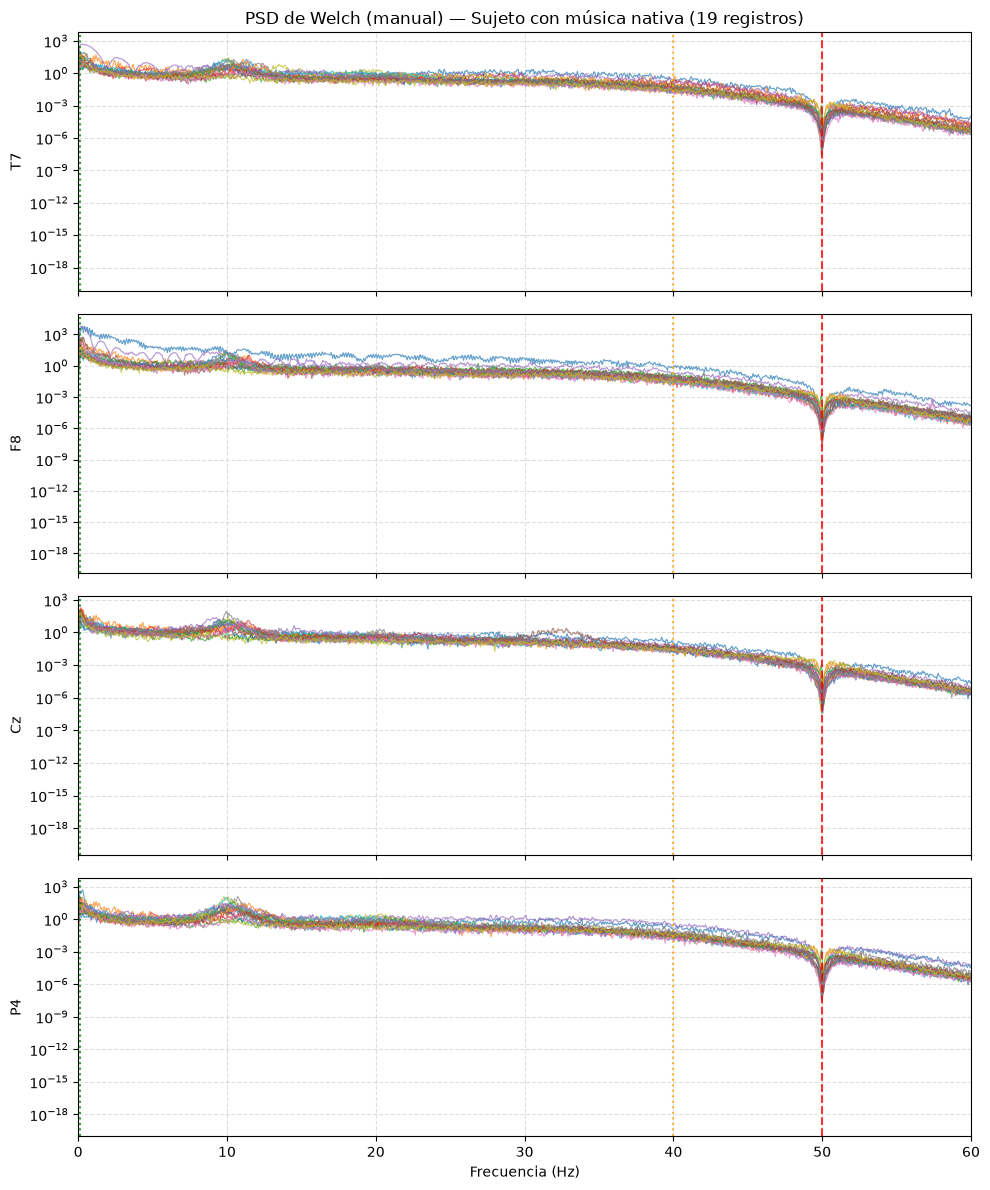

In [29]:
def calcular_psds(archivos):
    """PSD (Welch manual) de cada registro. Devuelve freq y {canal: matriz (n_registros, n_freq)}."""
    acumulado = {canal: [] for canal in canales}
    freq = None
    for nombre in archivos:
        df = pd.read_csv(os.path.join(ruta_datos, nombre), index_col=0)
        f, psd_dict = PSD.welch_eeg(df, fs, nperseg=nperseg, canales=canales)
        if freq is None:
            freq = f
        for canal in canales:
            acumulado[canal].append(psd_dict[canal])
    return freq, {canal: np.array(v) for canal, v in acumulado.items()}


def graficar_psd_individual(archivos, freq, psds, titulo):
    fig, axes = plt.subplots(len(canales), 1, figsize=(10, 3 * len(canales)), sharex=True)
    for ax, canal in zip(axes, canales):
        for nombre, psd in zip(archivos, psds[canal]):
            ax.semilogy(freq, psd, lw=0.8, alpha=0.7, label=nombre)
        for f_ref, (c, ls) in eeg.REFS_DEFAULT.items():
            ax.axvline(f_ref, color=c, ls=ls, alpha=0.8)
        ax.set_ylabel(canal)
        ax.set_xlim(0, 60)
        ax.grid(True, which="both", ls="--", alpha=0.4)
    axes[0].set_title(titulo)
    axes[-1].set_xlabel("Frecuencia (Hz)")
    plt.tight_layout()
    plt.show()


freq, psds_ex05 = calcular_psds(archivos_ex05)
graficar_psd_individual(
    archivos_ex05, freq, psds_ex05,
    f"PSD de Welch (manual) — Sujeto con música nativa ({len(archivos_ex05)} registros)")

Luego se realizó el mismo procedimiento para el ejercicio 6, que es el sujeto escuchando música en idioma no nativo.

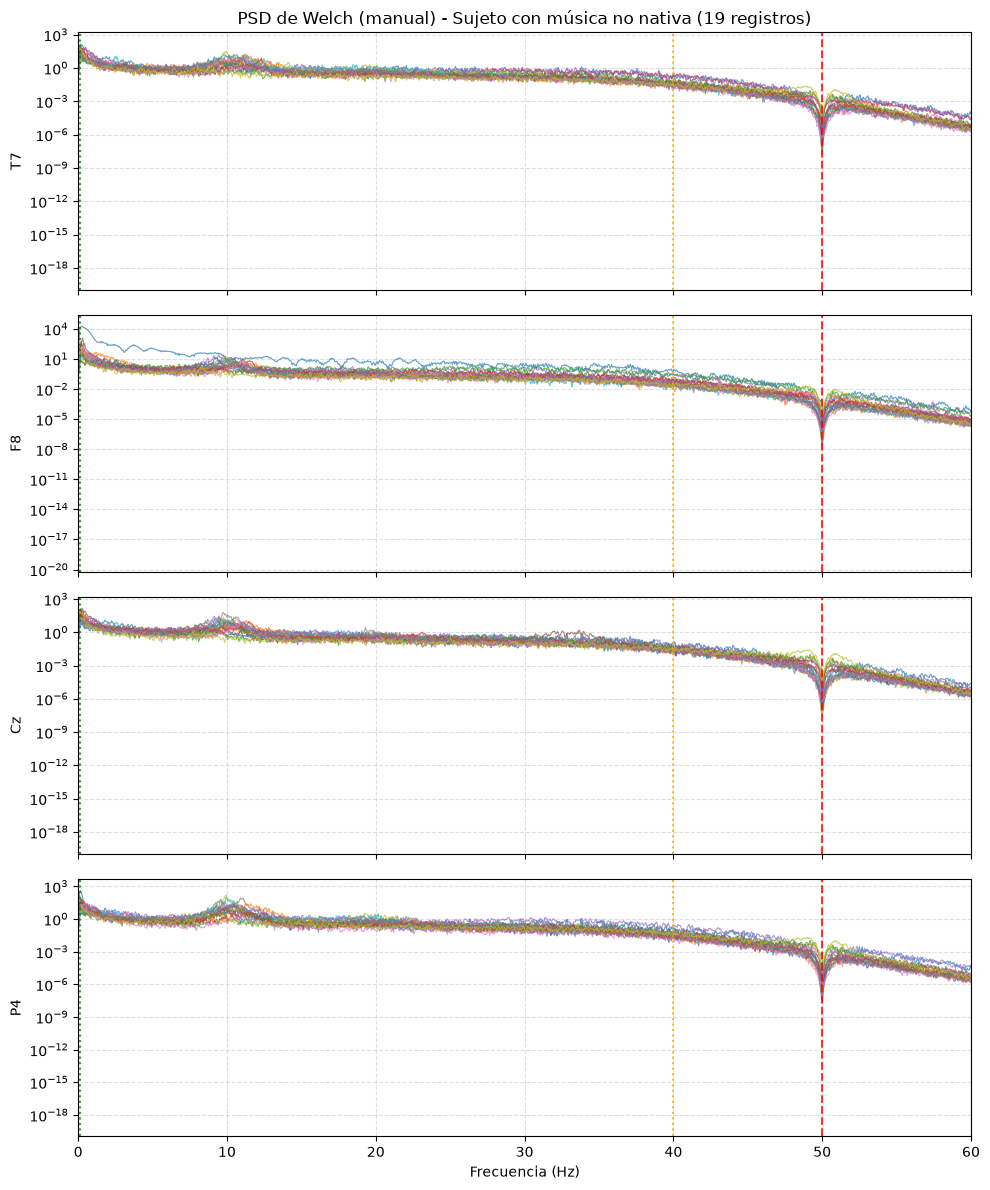

In [30]:
freq06,psds_ex06 = calcular_psds(archivos_ex06)
assert np.allclose(freq, freq06), "Las frecuencias de ex05 y ex06 deberían coincidir"

graficar_psd_individual(
    archivos_ex06, freq, psds_ex06,
    f"PSD de Welch (manual) - Sujeto con música no nativa ({len(archivos_ex06)} registros)")

### Verificación de `welch_per` contra SciPy

La implementación manual debería coincidir con `scipy.signal.welch` hasta error numérico. Se verifica contra los registros.

In [39]:
resultados = []

# Recorrer todos los registros ex05 y todos los canales
for archivo in archivos_ex05 + archivos_ex05:

    df = pd.read_csv(
        os.path.join(ruta_datos, archivo),
        index_col=0
    )

    for canal in df.columns:

        x = df[canal].to_numpy(dtype=float)

        # Implementación propia
        f1, p1 = welch_per(x, fs, nperseg, nperseg, noverlap)

        # Implementación de SciPy
        f2, p2 = scipy.signal.welch(
            x,
            fs,
            window="hann",
            nperseg=nperseg,
            noverlap=noverlap,
            nfft=nperseg,
            detrend="constant",
            scaling="density"
        )

        dimensiones_iguales = (
            f1.shape == f2.shape and p1.shape == p2.shape
        )

        if dimensiones_iguales:
            freq_iguales = np.allclose(f1, f2)
            psd_iguales = np.allclose(p1, p2)

            error_abs = np.max(np.abs(p1 - p2))
            error_rel = np.max(
                np.abs(p1 - p2) / np.maximum(np.abs(p2), 1e-20)
            )
        else:
            freq_iguales = False
            psd_iguales = False
            error_abs = np.nan
            error_rel = np.nan

        resultados.append({
            "registro": archivo,
            "canal": canal,
            "dimensiones_iguales": dimensiones_iguales,
            "freq_iguales": freq_iguales,
            "psd_iguales": psd_iguales,
            "error_abs_max": error_abs,
            "error_rel_max": error_rel
        })

# Resumen general
df_validacion = pd.DataFrame(resultados)

print("=" * 60)
print("VALIDACIÓN COMPLETA DE WELCH")
print("=" * 60)

print(f"\nTotal de comparaciones: {len(df_validacion)}")
print(f"Dimensiones iguales: {df_validacion['dimensiones_iguales'].all()}")
print(f"Frecuencias iguales: {df_validacion['freq_iguales'].all()}")
print(f"PSD equivalentes: {df_validacion['psd_iguales'].all()}")

print(f"Error absoluto máximo global: {df_validacion['error_abs_max'].max():.3e}")
print(f"Error relativo máximo global: {df_validacion['error_rel_max'].max():.3e}")

fallos = df_validacion[
    ~(
        df_validacion["dimensiones_iguales"] &
        df_validacion["freq_iguales"] &
        df_validacion["psd_iguales"]
    )
]

print(f"\nComparaciones con diferencias: {len(fallos)}")

if len(fallos) > 0:
    print(fallos.to_string(index=False))
else:
    print("Todas las comparaciones fueron satisfactorias.")



VALIDACIÓN COMPLETA DE WELCH

Total de comparaciones: 152
Dimensiones iguales: True
Frecuencias iguales: True
PSD equivalentes: True
Error absoluto máximo global: 2.728e-12
Error relativo máximo global: 4.780e-06

Comparaciones con diferencias: 0
Todas las comparaciones fueron satisfactorias.


En todos los casos se verificó la coincidencia de las dimensiones de los resultados y de los vectores de frecuencia. Asimismo, las estimaciones de PSD presentaron equivalencia numérica en la totalidad de las comparaciones (`np.allclose`), con un error absoluto máximo de $2.728 \times 10^{-12}$ y un error relativo máximo de $4.780 \times 10^{-6}$.

Estos resultados permiten concluir que la implementación propia reproduce satisfactoriamente los resultados de SciPy para los registros evaluados.

## 3.3 Mediana

Para estudiar mejor la PSD se aplica la mediana entre sujetos, de modo de tener una única curva por canal y condición. Se elige la mediana porque es menos sensible a outliers: la media se distorsiona mucho con valores extremos, mientras que la mediana no se mueve tanto porque no depende de la magnitud del valor extremo, solo de su posición relativa.

Primero se calcula para el experimento 5, que es los sujetos escuchando canciones en su idioma nativo. La banda sombreada en gris es el rango intercuartil (percentiles 25-75).

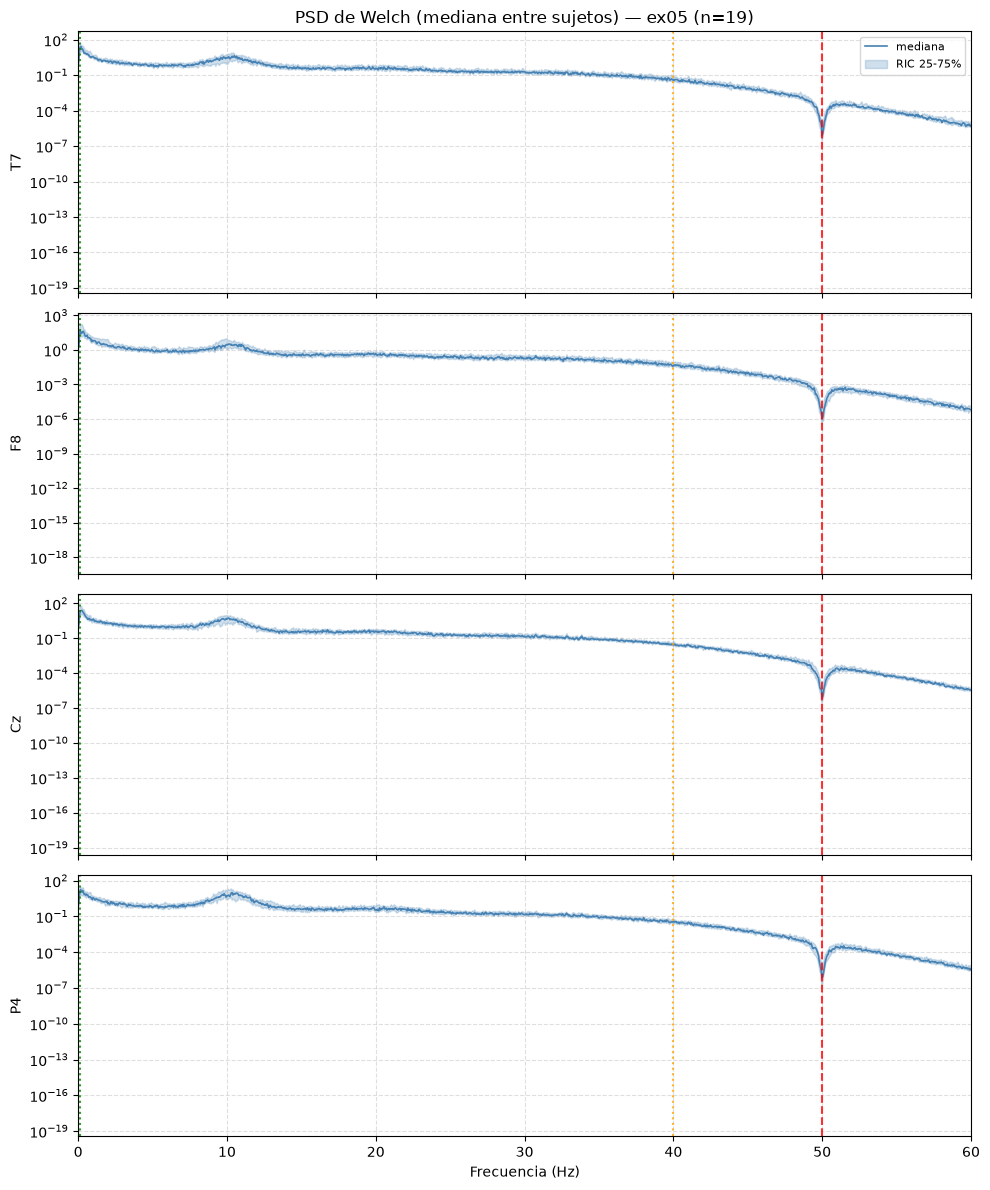

In [32]:
def graficar_mediana(freq, psds, titulo):
    """Grafica mediana + RIC por canal y devuelve {canal: mediana}."""
    medianas = {}
    fig, axes = plt.subplots(len(canales), 1, figsize=(10, 3 * len(canales)), sharex=True)
    for ax, canal in zip(axes, canales):
        matriz = psds[canal]  # (n_sujetos, n_freq)
        mediana = np.median(matriz, axis=0)
        p25 = np.percentile(matriz, 25, axis=0)
        p75 = np.percentile(matriz, 75, axis=0)
        medianas[canal] = mediana

        ax.semilogy(freq, mediana, color="steelblue", lw=1.2, label="mediana")
        ax.fill_between(freq, p25, p75, color="steelblue", alpha=0.25, label="RIC 25-75%")
        for f_ref, (c, ls) in eeg.REFS_DEFAULT.items():
            ax.axvline(f_ref, color=c, ls=ls, alpha=0.8)
        ax.set_ylabel(canal)
        ax.set_xlim(0, 60)
        ax.grid(True, which="both", ls="--", alpha=0.4)
    axes[0].set_title(titulo)
    axes[0].legend(fontsize=8)
    axes[-1].set_xlabel("Frecuencia (Hz)")
    plt.tight_layout()
    plt.show()
    return medianas


medianas_ex05 = graficar_mediana(
    freq, psds_ex05, f"PSD de Welch (mediana entre sujetos) — ex05 (n={len(archivos_ex05)})")

Luego se hace lo mismo para el experimento 6, que es los sujetos escuchando música en su idioma no nativo

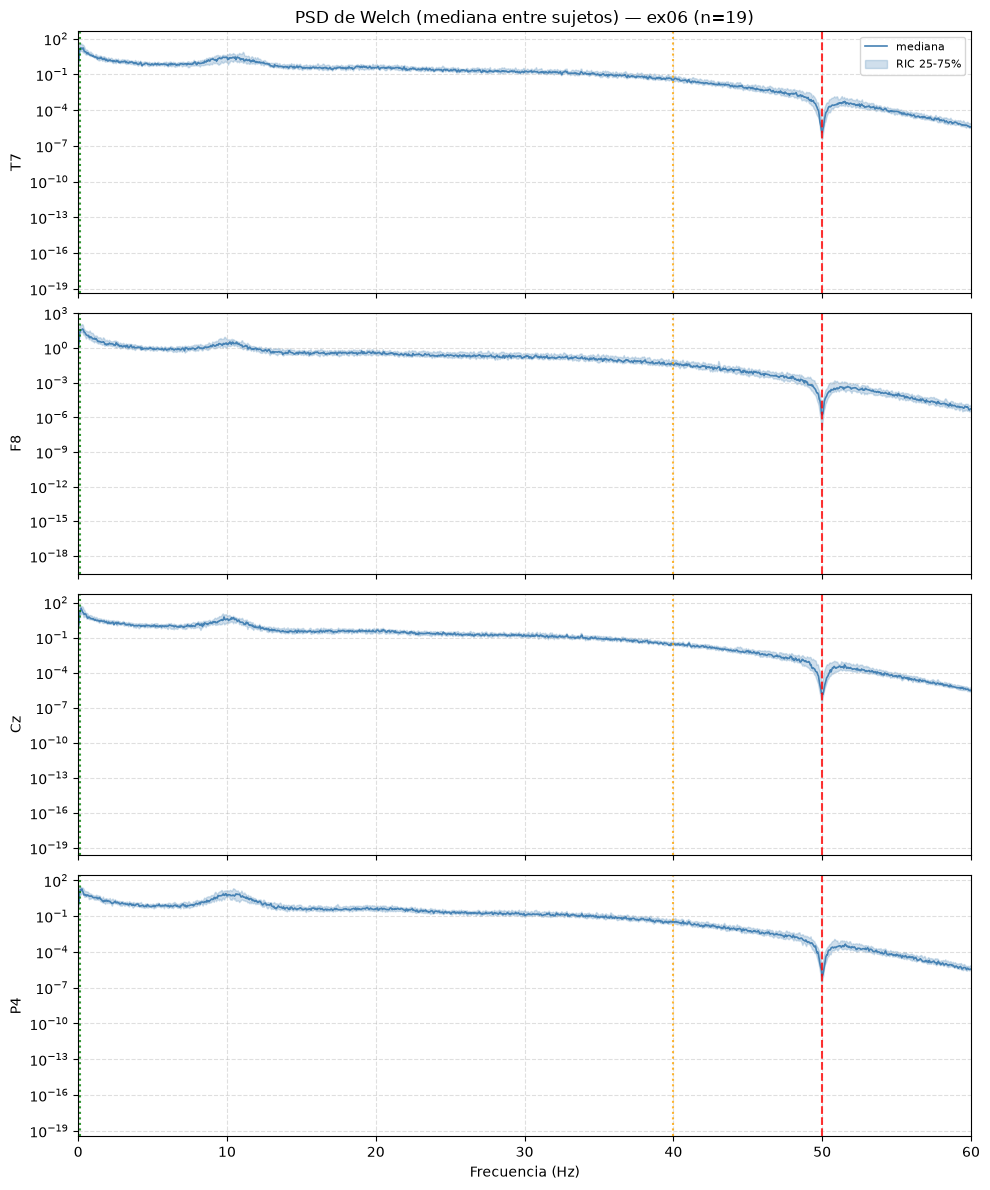

In [33]:
medianas_ex06 = graficar_mediana(
    freq, psds_ex06, f"PSD de Welch (mediana entre sujetos) — ex06 (n={len(archivos_ex06)})")

## 3.4. Cálculo de potencia por bandas

Con estas medianas se calcula la potencia por bandas para luego realizar el análisis.

Las bandas son:
- Delta (0,5 a 4 Hz)
- Theta (4 a 8 Hz)
- Alfa (8 a 13 Hz)
- Beta (13 a 30 Hz)
- Gamma (30 a 40 Hz)

El límite superior de gamma es 40 Hz porque es el borde del filtro pasabanda de los datos (0,5-40 Hz); por eso `f_total = (0.5, 40)` en `potencia_por_banda`. Cada banda incluye su límite inferior y excluye el superior (`f_min <= f < f_max`), así ningún bin cuenta en dos bandas. Como consecuencia, la última banda deja afuera el bin exacto de 40 Hz y las cinco relativas suman un poco menos que 1.

Se estudia la potencia relativa porque, al normalizar, las 5 bandas de cada registro suman (aproximadamente) 1, entonces se compara el "porcentaje de energía en cada banda" entre condiciones. Es una medida mucho más estable.

La lógica de este código se encuentra en `/analisis_PSD.py`. Como la mediana se calcula por canal, se calcula la potencia por banda de cada canal y se arma una tabla comparativa.

In [34]:
BANDAS = {
    "delta": (0.5, 4),
    "theta": (4, 8),
    "alfa":  (8, 13),
    "beta":  (13, 30),
    "gamma": (30, 40),
}

filas = []
for canal in canales:
    r05 = PSD.potencia_por_banda(freq, medianas_ex05[canal], BANDAS)
    r06 = PSD.potencia_por_banda(freq, medianas_ex06[canal], BANDAS)
    for banda in BANDAS:
        filas.append({
            "canal": canal, "banda": banda,
            "rel_nativo": r05[f"{banda}_rel"], "rel_no_nativo": r06[f"{banda}_rel"],
            "abs_nativo": r05[f"{banda}_abs"], "abs_no_nativo": r06[f"{banda}_abs"],
        })
df_bandas = pd.DataFrame(filas)

# --- Potencia relativa (%) ---
rel = df_bandas.pivot(index="banda", columns="canal", values=["rel_nativo", "rel_no_nativo"])
tabla_rel = pd.DataFrame(index=list(BANDAS))
for canal in canales:
    tabla_rel[f"{canal} nativo (%)"] = rel["rel_nativo"][canal] * 100
    tabla_rel[f"{canal} no nativo (%)"] = rel["rel_no_nativo"][canal] * 100
    tabla_rel[f"{canal} dif (%)"] = tabla_rel[f"{canal} no nativo (%)"] - tabla_rel[f"{canal} nativo (%)"]
print("Potencia relativa por banda y canal (dif = no nativo - nativo):")
display(tabla_rel.round(2))

# --- Suma de relativas (debería ser apenas menor que 100 %) ---
suma = df_bandas.groupby("canal")[["rel_nativo", "rel_no_nativo"]].sum() * 100
print("Suma de relativas por canal (%):")
display(suma.round(2))

Potencia relativa por banda y canal (dif = no nativo - nativo):


,T7 nativo (%),T7 no nativo (%),T7 dif (%),F8 nativo (%),F8 no nativo (%),F8 dif (%),Cz nativo (%),Cz no nativo (%),Cz dif (%),P4 nativo (%),P4 no nativo (%),P4 dif (%)
delta,26.06,29.17,3.11,41.96,41.85,-0.12,27.26,30.25,2.99,19.67,22.60,2.93
theta,10.92,11.91,0.99,10.87,11.58,0.71,13.61,14.05,0.44,8.60,9.02,0.42
alfa,36.88,32.99,-3.89,24.98,25.10,0.12,38.72,35.08,-3.64,52.04,48.98,-3.05
beta,21.25,21.21,-0.04,17.58,17.28,-0.29,16.94,16.96,0.02,16.53,16.19,-0.34
gamma,4.40,4.28,-0.13,4.19,3.73,-0.45,2.97,3.10,0.13,2.78,2.73,-0.05


Suma de relativas por canal (%):


,rel_nativo,rel_no_nativo
canal,,
Cz,99.51,99.45
F8,99.58,99.54
P4,99.60,99.52
T7,99.51,99.56


In [35]:
# --- Potencia absoluta (unidades de la PSD integradas en Hz, ej. µV²) ---
abs_ = df_bandas.pivot(index="banda", columns="canal", values=["abs_nativo", "abs_no_nativo"])
tabla_abs = pd.DataFrame(index=list(BANDAS))
for canal in canales:
    tabla_abs[f"{canal} nativo"] = abs_["abs_nativo"][canal]
    tabla_abs[f"{canal} no nativo"] = abs_["abs_no_nativo"][canal]
print("Potencia absoluta por banda y canal:")
display(tabla_abs)

Potencia absoluta por banda y canal:


,T7 nativo,T7 no nativo,F8 nativo,F8 no nativo,Cz nativo,Cz no nativo,P4 nativo,P4 no nativo
delta,6.585055,7.139551,12.610160,12.097324,7.871932,8.434855,6.646225,7.543876
theta,2.759064,2.915003,3.265130,3.346977,3.930790,3.917789,2.906215,3.011654
alfa,9.317852,8.073693,7.508133,7.256085,11.180373,9.780722,17.586342,16.352296
beta,5.369922,5.191058,5.282853,4.996871,4.891993,4.729778,5.585040,5.403771
gamma,1.112898,1.046446,1.257881,1.079049,0.858703,0.865147,0.939278,0.910556


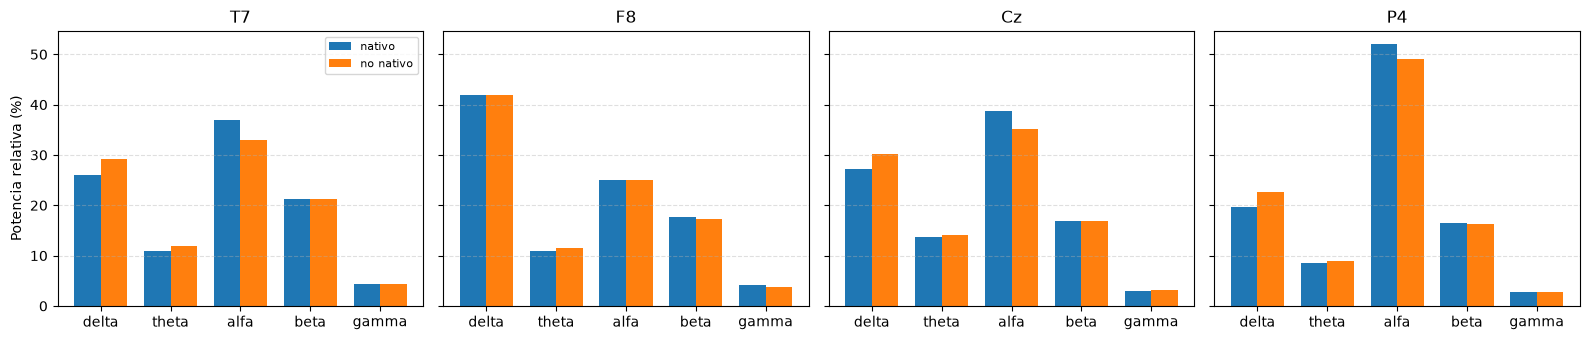

In [36]:
# --- Gráfico: potencia relativa por banda, nativo vs no nativo, un panel por canal ---
fig, axes = plt.subplots(1, len(canales), figsize=(4 * len(canales), 3.5), sharey=True)
x = np.arange(len(BANDAS))
ancho = 0.38
for ax, canal in zip(axes, canales):
    sub = df_bandas[df_bandas["canal"] == canal].set_index("banda").loc[list(BANDAS)]
    ax.bar(x - ancho / 2, sub["rel_nativo"] * 100, ancho, label="nativo")
    ax.bar(x + ancho / 2, sub["rel_no_nativo"] * 100, ancho, label="no nativo")
    ax.set_xticks(x)
    ax.set_xticklabels(list(BANDAS))
    ax.set_title(canal)
    ax.grid(True, axis="y", ls="--", alpha=0.4)
axes[0].set_ylabel("Potencia relativa (%)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3.5. Análisis

La tabla de la sección 3.4 muestra cómo se reparte la potencia relativa entre bandas en cada canal, para música en idioma nativo (ex05) y no nativo (ex06). Las diferencias se expresan como no nativo menos nativo, en puntos porcentuales (pp).

En T7, Cz y P4 la banda alfa concentra la mayor parte de la potencia relativa, seguida por delta. Un pico marcado en alfa es compatible con un estado de reposo, posiblemente con los ojos cerrados, aunque la PSD por sí sola no permite confirmarlo. En F8 el comportamiento es distinto: domina delta y alfa baja. Esto podría deberse a actividad frontal o a artefactos oculares residuales.

En T7, Cz y P4 aparece el mismo patrón al pasar de música nativa a no nativa:
- La potencia relativa de **alfa disminuye** alrededor de 3 puntos porcentuales.
- La de **delta aumenta** cerca de 3 puntos porcentuales también.
- **Theta aumenta levemente** en los cuatro canales.

La potencia absoluta acompaña esta tendencia en esos canales: alfa baja y delta sube. En F8 las diferencias son prácticamente nulas, por lo que no se observa un efecto en esas bandas.

Posible interpretación: una menor potencia alfa relativa junto con un aumento de delta y theta podría reflejar menor relajación y mayor demanda cognitiva al escuchar música en un idioma no nativo, lo cual es coherente con lo que se plantea en la literatura. Se presenta como una hipótesis y no como una conclusión.

Limitaciones: estos resultados provienen de la mediana entre 19 sujetos. Esa mediana resume al grupo en una sola curva por canal, por lo que no permite saber cuánta de la diferencia observada se debe a variabilidad entre personas ni si es estadísticamente significativa. Una diferencia de ≈3 pp podría estar dentro de esa variabilidad. Por eso en la sección 4 se repite el procedimiento por sujeto, lo que permite comparar ambas condiciones dentro de cada persona y aplicar una prueba estadística.

Como se puede observar en la tabla hay un pico en la onda alfa, esto puede significar que la persona se encuentra con los ojos cerrados, se puede observar que el nativo  posee más potencia relativa en la onda alfa que el no nativo , esto se puede dar porque la persona escuchando música no nativa debe estar más concentrada por lo tanto menos relajada y perderá potencia en la banda alfa. Esto también puede verse en las ondas delta, hay más potencia relativaa en la onda delta del no nativo que del nativo, esto puede significar que el no nativo requiere más esfuerzo cognitivo que el naitvo.

Si bien las diferencias pueden darse por lo nombrado, también pueden darse por errores en la estadistica y en que la mediana no tome valores tan correctos para el analisis, por eso en la sección 4 se realizó este mismo procedimiento para cada sujeto.